## 1. Dataset Preparation

### 1.1 Data Annotation

In [13]:
import kagglehub
import os
from pathlib import Path
import pandas as pd

os.environ['KAGGLEHUB_CACHE'] = str(Path.cwd() / "data") # Set cache directory to ./data

data_root_dir = kagglehub.dataset_download("tongpython/cat-and-dog")
print("Path to dataset cache:", data_root_dir)
train_cat_dir = Path(data_root_dir) / "training_set" / "training_set" / "cats"
train_dog_dir = Path(data_root_dir) / "training_set" / "training_set" / "dogs"
val_cat_dir = Path(data_root_dir) / "test_set" / "test_set" / "cats"
val_dog_dir = Path(data_root_dir) / "test_set" / "test_set" / "dogs"
# Glob training files
train_cat_files = list(train_cat_dir.glob("**/*.jpg"))
train_dog_files = list(train_dog_dir.glob("**/*.jpg"))
print(f"There are {len(train_cat_files)} cat images, and {len(train_dog_files)} dog images in the training dataset")
df_train = pd.DataFrame({
    'path': list(train_cat_files) + list(train_dog_files),
    'label': ['cat'] * len(list(train_cat_files)) + ['dog'] * len(list(train_dog_files))
})
df_train.to_csv('annotations_train.csv', header=False, index=False)  

# Glob validation files
val_cat_files = list(val_cat_dir.glob("**/*.jpg"))
val_dog_files = list(val_dog_dir.glob("**/*.jpg"))
print(f"There are {len(val_cat_files)} cat images, and {len(val_dog_files)} dog images in the validation dataset")
df_val = pd.DataFrame({
    'path': list(val_cat_files) + list(val_dog_files),
    'label': ['cat'] * len(list(val_cat_files)) + ['dog'] * len(list(val_dog_files))
})
df_val.to_csv('annotations_val.csv', header=False, index=False)  

Path to dataset cache: /home/pbdn/Documents/3321/3321example-cats_vs_dogs/data/datasets/tongpython/cat-and-dog/versions/1
There are 4000 cat images, and 4005 dog images in the training dataset
There are 1011 cat images, and 1012 dog images in the validation dataset


### 1.2 PyTorch Dataset Creation


In [14]:
from torchvision.io import decode_image, ImageReadMode
from torchvision.transforms.v2 import Resize
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
np.random.seed(3321)

class CatDogDataset(Dataset):
    def __init__(self, annotations_file):
        self.imgs_info = pd.read_csv(annotations_file, header=None)

    def __len__(self):
        return len(self.imgs_info)
    
    def __getitem__(self, idx):
        img_path = self.imgs_info.iloc[idx, 0]
        raw_img = decode_image(img_path, mode=ImageReadMode.RGB)
        img_resize = Resize((64, 64))(raw_img)
        image = img_resize.reshape(1, -1) / 255.  # normalize to [0, 1] and flatten
        category = np.array([1., 0.]) if self.imgs_info.iloc[idx, 1] == 'cat' else np.array([0., 1.])  # one-hot encoding
        sample = {'image': image.squeeze(), 'category': category.squeeze()}

        return sample

### 1.3 Data Pre-Processing


training features batch shape: torch.Size([128, 12288]), a sample features:
 tensor([0.1725, 0.1765, 0.1804,  ..., 0.6784, 0.6745, 0.6745])
training labels batch shape: torch.Size([128, 2]), a sample label: tensor([1., 0.], dtype=torch.float64)
validation features batch shape: torch.Size([2023, 12288]), a sample features:
 tensor([0.4471, 0.4824, 0.4824,  ..., 0.7804, 0.7922, 0.7725])
validation labels batch shape: torch.Size([2023, 2]), a sample label: tensor([1., 0.], dtype=torch.float64)


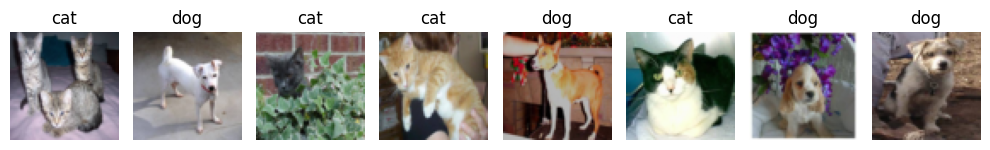

In [15]:
# Extract features/images and targets/labels
dataset_train = CatDogDataset(annotations_file='annotations_train.csv')
dataset_val = CatDogDataset(annotations_file='annotations_val.csv')

# Create data loaders
batch_size = 128
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)  # large batch size to get all data in one batch
dataloader_val = DataLoader(dataset_val, batch_size=10000, shuffle=False)
# Extract a batch of data from dataloaders
sample_batch_train = next(iter(dataloader_train))
sample_batch_val = next(iter(dataloader_val))

# Probe the data
print(f"training features batch shape: {sample_batch_train['image'].shape}, a sample features:\n {sample_batch_train['image'][0]}")
print(f"training labels batch shape: {sample_batch_train['category'].shape}, a sample label: {sample_batch_train['category'][0]}")
print(f"validation features batch shape: {sample_batch_val['image'].shape}, a sample features:\n {sample_batch_val['image'][0]}")
print(f"validation labels batch shape: {sample_batch_val['category'].shape}, a sample label: {sample_batch_val['category'][0]}")    

# Visualize a few sample images
fig, axs = plt.subplots(1, 8, figsize=(10, 5))
for i in range(8):
    sample_img = np.transpose(sample_batch_train['image'][i].reshape(3, 64, 64), (1, 2, 0))  # reconstruct image to (H, W, C) format
    sample_cls = sample_batch_train['category'][i]
    axs[i] = plt.subplot(1, 8, i + 1)
    axs[i].set_title(f'{"dog" if sample_cls[1] == 1. else "cat"}')
    axs[i].axis('off')
    axs[i].imshow(sample_img)  # image is already in (H, W, C) format
plt.tight_layout()

# Rerun this cell to get different samples.

## 2. Multi-Layer Perceptron Model

A general feature transformation from a previous layer $[l-1]$ to the next layer $[l]$ can be defined as:

$$\mathbf{X}^{[l]} = a(\mathbf{Z}^{[l]}) = a(\mathbf{X}^{[l-1]} \cdot \mathbf{W}^{[l]T} + \mathbf{b}^{[l]}) $$

where $\mathbf{X}^{[l-1]}$ is the input features matrix from layer $[l-1]$. $\mathbf{Z}^{[l]}$ is the linearly transformed $\mathbf{X}^{[l-1]}$ with weight matrix, $\mathbf{W}^{[l]}$ and bias vector, $\mathbf{b}^{[l]}$. $\mathbf{X}^{[l]}$ is the output features matrix for layer $[l]$, which is $\mathbf{Z}^{[l]}$ activated by function $a(\cdot)$. 

## 2.1 Activation Functions

1. Sigmoid

$$\sigma(z) = \frac{1}{1 + e^{-z}} $$
$$\sigma'(x) = \sigma(z) (1 - \sigma(z)) $$

2. Hyper-Tangential

$$\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}} $$
$$\tanh'(z) = (1 - \tanh^2(z)) $$

3. Rectified Linear Unit (ReLU)
> The modern activation function

$$
ReLU(z) = 
\begin{cases}
    z &\text{if $z > 0$} \\
    0 &\text{otherwise}
\end{cases}
$$

$$
ReLU'(z) = 
\begin{cases}
    1 &\text{if $z > 0$} \\
    0 &\text{otherwise}
\end{cases}
$$

4. Leaky ReLU
> ReLU Pro Max

$$
LR(z) = 
\begin{cases}
    z &\text{if $z > 0$} \\
    az &\text{otherwise ($a$ is a constant)}
\end{cases}
$$

$$
LR'(z) = 
\begin{cases}
    1 &\text{if $z > 0$} \\
    a &\text{otherwise}
\end{cases}
$$

5. For classification problems, softmax activation function are usually applied to the output layer ($[L]$) **only**, to encode the features into probability distributions.

$$
\hat{\mathbf{Y}} = a(\mathbf{Z}^{[L]}) = \frac {e^{Z^{[L]}}} {\sum e^{Z^{[L]}} \text{, axis}=1 \text{, keepdims}=\text{True}}
$$ 

6. For regression problems, no activation will be applied to linear transformed features in the output layer. So, they are also called linear activated output features.


In [16]:
def sigmoid(z):
    """ Sigmoid function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return 1 / (1 + np.exp(-z))

def relu(z):
    """ ReLU function
    Args:
        z: independent variable, could be an arrary of any shape or a scalar. 
    Returns:
        dependent variable, could be an arrary of any shape or a scalar. 
    """
    return np.maximum(0, z)

def softmax(z):
    """ Softmax function
    Args:
        z: independent variable, 2d array with shape (# samples, # features)
    Returns:
        probabilities: dependent variable, 2d array with shape (# samples, # features)
    """
    probabilities = np.exp(z) / np.sum(np.exp(z), axis=-1, keepdims=True)
    return probabilities

# Sanity check
z_dummy = np.linspace(-5, 5, 10).reshape(2, 5)
print(f"Input = \n{z_dummy}")
print(f"Sigmoid activation = \n{sigmoid(z_dummy)}")
print(f"ReLU activation = \n{relu(z_dummy)}")
print(f"Softmax activation = \n{softmax(z_dummy)}")



Input = 
[[-5.         -3.88888889 -2.77777778 -1.66666667 -0.55555556]
 [ 0.55555556  1.66666667  2.77777778  3.88888889  5.        ]]
Sigmoid activation = 
[[0.00669285 0.02005754 0.0585369  0.1588691  0.36457644]
 [0.63542356 0.8411309  0.9414631  0.97994246 0.99330715]]
ReLU activation = 
[[0.         0.         0.         0.         0.        ]
 [0.55555556 1.66666667 2.77777778 3.88888889 5.        ]]
Softmax activation = 
[[0.00790828 0.02402324 0.07297615 0.22168197 0.67341036]
 [0.00790828 0.02402324 0.07297615 0.22168197 0.67341036]]


### 2.2. Parameter Initialization


In [17]:
def init_params(in_dims, hidden_dims, out_dims):
    """
    Initialize the parameters of the MLP model.
    Args:
        in_dims: number of input dimensions.
        hidden_dims: tuple of hidden layer dimensions.
        out_dims: number of output dimensions.
    Returns:
        params: dictionary containing the initialized weights and biases.
    """
    layer_dims = (in_dims, *hidden_dims, out_dims)
    params = {}
    for l in range(len(layer_dims) - 1):
        params[f'W{l+1}'] = np.random.normal(loc=0, scale=0.1, size=(layer_dims[l + 1], layer_dims[l]))
        params[f'b{l+1}'] = np.random.normal(loc=0, scale=0.0001, size=(1, layer_dims[l + 1]))
    return params

# Example usage
np.random.seed(3)  # for reproducibility
params_dummy = init_params(in_dims=sample_batch_train['image'].shape[1], hidden_dims=(4, 3), out_dims=2)
print(params_dummy)
for key in params_dummy:
    print(f"{key}: shape {params_dummy[key].shape}")



{'W1': array([[ 0.17886285,  0.04365099,  0.00964975, ...,  0.07420327,
         0.0777721 , -0.20441006],
       [-0.20347414, -0.12771078, -0.08450469, ..., -0.15928584,
         0.11897585,  0.13690896],
       [ 0.07363235,  0.10400325, -0.06107588, ..., -0.07199719,
         0.13425217, -0.0194119 ],
       [-0.03141553, -0.02987701,  0.06186741, ..., -0.02133808,
        -0.00591601, -0.00090763]], shape=(4, 12288)), 'b1': array([[-3.76098834e-05,  4.78080018e-05,  1.33795636e-04,
        -1.26629389e-04]]), 'W2': array([[-0.02085974,  0.11915952, -0.12430476,  0.00050952],
       [-0.09721265, -0.06123586, -0.07497234,  0.01697797],
       [ 0.05372288,  0.0311052 ,  0.00204229, -0.14640231]]), 'b2': array([[-9.31087539e-05,  5.84929469e-05,  9.76949570e-05]]), 'W3': array([[ 0.13380422, -0.00350686,  0.03678739],
       [-0.07292948, -0.04589545, -0.23943169]]), 'b3': array([[-4.55391846e-05,  6.27715186e-05]])}
W1: shape (4, 12288)
b1: shape (1, 4)
W2: shape (3, 4)
b2: shape (

### 2.3 Model Construction
1. Linearly transform features from previous layer: $\mathbf{Z}^{[l]} = \mathbf{X}^{[l-1]} \cdot \mathbf{W}^{[l]T} + \mathbf{b}^{[l]})$.
2. Apply your choice of activation function on $\mathbf{Z}^{[l]}$, so that the features in the next layer will be: $\mathbf{X}^{[l]} = a(\mathbf{Z}^{[l]})$ 
3. Apply your choice of activation function on the last layer $\mathbf{Z}^{[L]}$, so that the model's output will fit the problem's needs: $\hat{\mathbf{Y}} = a(\mathbf{Z}^{[L]})$

In [18]:
def linear(in_features, weights, biases):
    """ Linear function
    Args:
        in_features: input feature matrix, 2d array with shape (# samples, # input features)
        weights: weight parameter matrix, 2d array with shape (# next layer features , # input features)
        biases: bias parameter vector, 2d array with shape (1, # next layer features)
    Returns:
        linear_output: linear model output feature matrix, 2d array with shape (# samples, # next layer features)
    """
    linear_output = in_features @ weights.T + biases
    return linear_output

def forward(in_features, params, hidden_activation=None, out_activation=None):
    """ Forward function
    Args:
        in_features: feature matrix, 2d array with shape (# samples, # pixels)
        params: a dictionary of weights and biases
            params = {
                'W_1': weight matrix of the first layer, 2d array with shape (# hidden features in 1st layer, # input features)
                'b_1': bias vector of the first layer, 2d array with shape (1, # hidden features in 1st layer)
                ...
                'W_L': weight matrix of the last layer, 2d array with shape (# hidden features in output layer, # hidden features in L-1 layer)
                'b_L': bias vector of the last layer, 2d array with shape (1, # output features)
            }
        hidden_activation: activation function for hidden layers, could be sigmoid, relu, etc. If None, no activation is applied.
        out_activation: activation function for output layer, could be sigmoid, softmax, etc. If None, no activation is applied.
    Returns:
        predictions: predicted probabilities, a column vector or 2d array with shape (# samples, # output features)
        cache: linear activated features
    """

    num_layers = len(params) // 2
    # Input layer
    cache = {'X0': in_features}
    # Hidden layers
    for i in range(num_layers - 1):
        cache[f'Z{i+1}'] = linear(cache[f'X{i}'], params[f'W{i+1}'], params[f'b{i+1}'])
        if hidden_activation=="relu":
            cache[f'X{i+1}'] = relu(cache[f'Z{i+1}'])
        elif hidden_activation=="sigmoid":
            cache[f'X{i+1}'] = sigmoid(cache[f'Z{i+1}'])
        else:
            cache[f'X{i+1}'] = cache[f'Z{i+1}']
    # Output layer
    cache[f'Z{num_layers}'] = linear(cache[f'X{num_layers-1}'], params[f'W{num_layers}'], params[f'b{num_layers}'])
    if out_activation=="relu":
        predictions = relu(cache[f'Z{num_layers}'])
    elif out_activation=="sigmoid":
        predictions = sigmoid(cache[f'Z{num_layers}'])
    elif out_activation=="softmax":
        predictions = softmax(cache[f'Z{num_layers}'])
    else:
        predictions = cache[f'Z{num_layers}']
    return predictions, cache

# Sanity check
preds_dummy, cache_dummy = forward(sample_batch_train['image'].numpy(), params_dummy, "relu", "softmax")
print(f"Features: {list(cache_dummy.keys())[:]}")
print(f"Shape of dummy predictions: {preds_dummy.shape}")
print(f"Dummy prediction samples:\n{preds_dummy[:10]}")


Features: ['X0', 'Z1', 'X1', 'Z2', 'X2', 'Z3']
Shape of dummy predictions: (128, 2)
Dummy prediction samples:
[[0.49997292 0.50002708]
 [0.49997292 0.50002708]
 [0.50861783 0.49138217]
 [0.49997292 0.50002708]
 [0.49997292 0.50002708]
 [0.50093516 0.49906484]
 [0.50311819 0.49688181]
 [0.5013762  0.4986238 ]
 [0.50124523 0.49875477]
 [0.49997292 0.50002708]]


## 3. Model Evaluation

### 3.1. Cross Entropy Loss
The CE function is more appropriate in classification tasks.
$$
\mathcal{L}(\hat{\mathbf{Y}}, \mathbf{Y}) = \frac{1}{M} \sum_{m=1}^M (\sum -^{(m)}\mathbf{Y} * \ln ^{(m)} \hat{\mathbf{Y}}, \text{axis}=-1)
$$ 
$\mathbf{Y}$ is one-hot encoded label matrix.

### 3.2. Classification Metrics
#### 3.2.1. Accuracy
$$
A = \frac{TN + TP}{TN + TP + FN + FP}
$$

#### 3.2.2. Precision
$$
P = \frac{TP}{TP + FP}
$$

#### 3.2.3. Recall/Sensitivity
$$
A = \frac{TP}{TP + FN}
$$

In [19]:
def ce_loss(predictions, labels):
    """ Cross Entropy Loss
    Args:    return predictions, cache

    Returns:
    """
    sample_wise_losses = (-labels * np.log(predictions + 1e-15)).sum(axis=-1)
    return sample_wise_losses.mean()

def classify(predictions):
    one_hot_ids = predictions.argmax(axis=-1)
    pred_classes = np.zeros_like(predictions)
    pred_classes[np.arange(predictions.shape[0]), one_hot_ids] = 1
    return pred_classes

def accuracy(predictions, labels):
    predicted_classes = classify(predictions)
    acc = np.mean((predicted_classes == labels).all(axis=-1))
    return acc

# Check functionalities
loss = ce_loss(preds_dummy, sample_batch_train['category'].numpy())
acc = accuracy(preds_dummy, sample_batch_train['category'].numpy())

print(f"Dummy model BCE loss: {ce_loss(preds_dummy, sample_batch_train['category'].numpy())}")
# print(f"True label samples: \n{sample_batch_train['category'].numpy()[:4]}")
print(f"Dummy classification samples: \n{classify(preds_dummy)[:10]}")
print(f"Dummy model accuracy: {accuracy(preds_dummy, sample_batch_train['category'].numpy()) * 100}%")


Dummy model BCE loss: 0.693366927470352
Dummy classification samples: 
[[0. 1.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]]
Dummy model accuracy: 47.65625%


## 4. Gradients of Loss

For $l$ from $L$ to 1:
$$
\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[l]}} = \frac{\partial \mathcal{L}}{\partial \mathbf{X}^{[l]}} * a'(\mathbf{Z}^{[l]})
$$

$$
\frac{\partial \mathcal{L}}{\partial \mathbf{W}^{[l]}} = (\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[l]}})^T \cdot \mathbf{X}^{[l-1]}
$$

$$
\frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[l]}} = \text{mean}(\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[l]}}, \text{axis}=0, \text{keepdims}) 
$$

$$
\frac{\partial \mathcal{L}}{\partial \mathbf{X}^{[l-1]}} = \frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[l]}} \cdot \mathbf{W}^{[l]}
$$

The special case for last layer:
$$
\frac{\partial \mathcal{L}}{\partial \mathbf{Z}^{[L]}} = \frac{\partial \mathcal{L}}{\partial \hat{\mathbf{Y}}} \cdot \frac{\partial \hat{\mathbf{Y}}}{\partial \mathbf{Z}^{[L]}} = \hat{\mathbf{Y}} - \mathbf{Y}
$$

In [20]:
def d_sigmoid(x):
    return sigmoid(x) * (1 - sigmoid(x))

def d_relu(x):
    return (x > 0).astype(float)

def backward(predictions, labels, cache, params, activation="relu"):
    num_layers = len(params) // 2
    grads = {f'dZ{num_layers}': predictions - labels}
    for i in reversed(range(num_layers)):
        grads[f'dW{i+1}'] = grads[f'dZ{i+1}'].T @ cache['X' + str(i)]
        grads[f'db{i+1}'] = np.mean(grads[f'dZ{i+1}'], axis=0, keepdims=True)
        if i==0:
            break  
        grads[f'dX{i}'] = grads[f'dZ{i+1}'] @ params[f'W{i+1}']
        if activation == 'relu':
            grads[f'dZ{i}'] = grads[f'dX{i}'] * d_relu(cache[f'Z{i}'])
        elif activation == 'sigmoid':
            grads[f'dZ{i}'] = grads[f'dX{i}'] * d_sigmoid(cache[f'Z{i}'])
        else:
            grads[f'dZ{i}'] = grads[f'dX{i}']

    return grads

grads_dummy = backward(preds_dummy, sample_batch_train['category'].numpy(), cache_dummy, params_dummy)
# print(grads_dummy)
for key in grads_dummy:
    print(f"{key}: shape {grads_dummy[key].shape}")


dZ3: shape (128, 2)
dW3: shape (2, 3)
db3: shape (1, 2)
dX2: shape (128, 3)
dZ2: shape (128, 3)
dW2: shape (3, 4)
db2: shape (1, 3)
dX1: shape (128, 4)
dZ1: shape (128, 4)
dW1: shape (4, 12288)
db1: shape (1, 4)


## 5. Gradient Descent

In [21]:
# Hyper-parameters
num_iters = 300
learning_rate = 1e-4
# Model parameters
params = init_params(in_dims=sample_batch_train['image'].numpy().shape[-1], hidden_dims=(32, 32), out_dims=2)
# Reserve metrics storage
losses_train, losses_val = [], []
accuracies_train, accuracies_val = [], []

# LOOP
for ep in range(num_iters):
    ep_loss, ep_acc = [], []
    for bi, batch_train in enumerate(dataloader_train):
        preds_train, cache_train = forward(batch_train['image'].numpy(), params, "relu", "softmax")
        batch_loss = ce_loss(preds_train, batch_train['category'].numpy())
        batch_acc = accuracy(preds_train, batch_train['category'].numpy())
        ep_loss.append(batch_loss)
        ep_acc.append(batch_acc)
        if not (bi+1) % 10:
            print(f"Training epoch {ep+1} batch {bi+1} loss: {batch_loss}, accuracy: {batch_acc}")
        grads = backward(preds_train, batch_train['category'].numpy(), cache_train, params, activation="relu")
        for l in range(len(params_dummy) // 2):
            params[f'W{l+1}'] = params[f'W{l+1}'] - learning_rate * grads[f'dW{l+1}']
            params[f'b{l+1}'] = params[f'b{l+1}'] - learning_rate * grads[f'db{l+1}']
    # Validate updated model on entire val dataset
    data_val = next(iter(dataloader_val))
    preds_val, _ = forward(data_val['image'].numpy(), params, "relu", "softmax")
    loss_val = ce_loss(preds_val, data_val['category'].numpy())
    acc_val = accuracy(preds_val, data_val['category'].numpy())
    print(f"Epoch {ep+1} validation accuracy: {acc_val}")    
    # Summarize epoch
    losses_train.append(np.mean(ep_loss))
    accuracies_train.append(np.mean(ep_acc))
    losses_val.append(loss_val)
    accuracies_val.append(acc_val)


Training epoch 1 batch 10 loss: 0.6886892673688176, accuracy: 0.6015625
Training epoch 1 batch 20 loss: 0.68895379230243, accuracy: 0.53125
Training epoch 1 batch 30 loss: 0.6614039023454183, accuracy: 0.6015625
Training epoch 1 batch 40 loss: 0.6916839273043868, accuracy: 0.5234375
Training epoch 1 batch 50 loss: 0.7020438375098168, accuracy: 0.546875
Training epoch 1 batch 60 loss: 0.6794559743656707, accuracy: 0.5859375
Epoch 1 validation accuracy: 0.5254572417202175
Training epoch 2 batch 10 loss: 0.682481888490418, accuracy: 0.578125
Training epoch 2 batch 20 loss: 0.7086678957692136, accuracy: 0.453125
Training epoch 2 batch 30 loss: 0.7089329998847025, accuracy: 0.46875
Training epoch 2 batch 40 loss: 0.6702383683363078, accuracy: 0.5703125
Training epoch 2 batch 50 loss: 0.6841079148193493, accuracy: 0.546875
Training epoch 2 batch 60 loss: 0.674330146568725, accuracy: 0.59375
Epoch 2 validation accuracy: 0.551161641127039
Training epoch 3 batch 10 loss: 0.6868833863919719, acc

(0.0, 1.0)

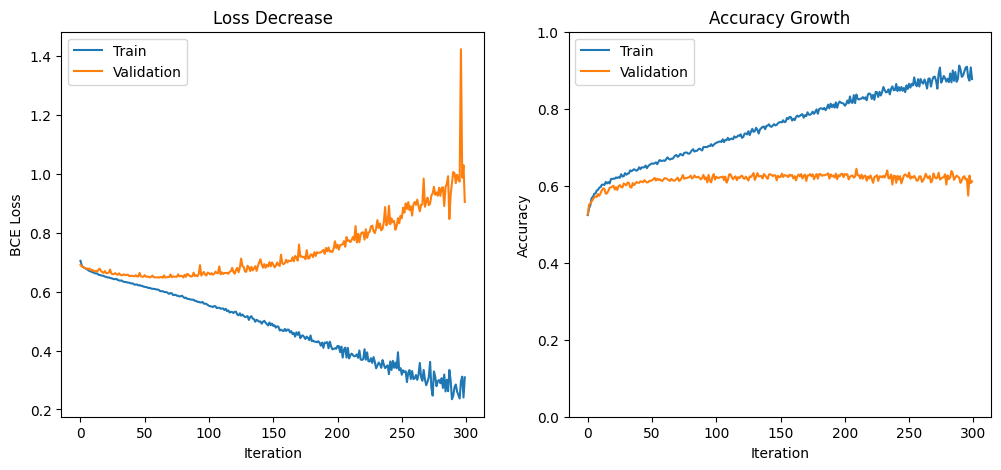

In [22]:
# Plot loss and accuracy curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(num_iters), losses_train, range(num_iters), losses_val)
plt.legend(['Train', 'Validation'])
plt.title("Loss Decrease")
plt.xlabel("Iteration")
plt.ylabel("BCE Loss")
plt.subplot(1, 2, 2)
plt.plot(range(num_iters), accuracies_train, range(num_iters), accuracies_val)
plt.legend(['Train', 'Validation'])
plt.title("Accuracy Growth")
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.ylim(0, 1)



Text(0.5, 1.0, 'Confusion Matrix - Validation Data')

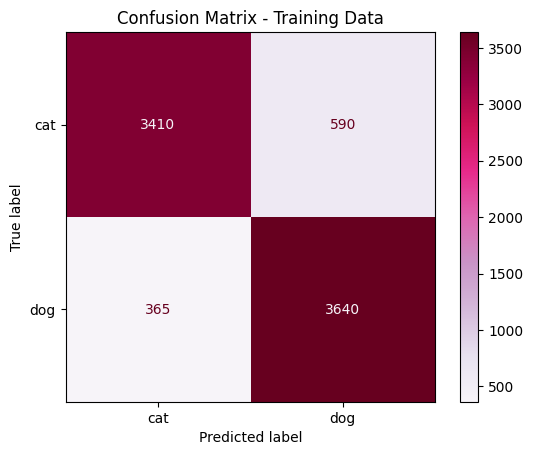

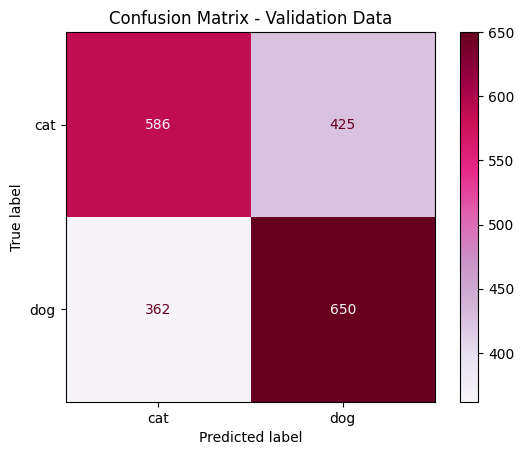

In [23]:
# Confusion Matrix for Test Data
dloader_train_all = DataLoader(dataset_train, batch_size=10000, shuffle=False)  # large batch size to get all data in one batch
data_train_all = next(iter(dloader_train_all))
labels_train_all = data_train_all['category'].numpy().argmax(axis=-1)
preds_train_all, _ = forward(data_train_all['image'].numpy(), params, "relu", "softmax")
predcls_train_all = preds_train_all.argmax(axis=-1)
# print(predcls_train_all)
# print(labels_train_all)
predcls_val_all = preds_val.argmax(axis=-1)
labels_val_all = data_val['category'].numpy().argmax(axis=-1)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_train = confusion_matrix(labels_train_all, predcls_train_all)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=["cat", "dog"])
disp_train.plot(cmap='PuRd')
plt.title('Confusion Matrix - Training Data')
cm_val = confusion_matrix(labels_val_all, predcls_val_all)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=["cat", "dog"])
disp_test.plot(cmap='PuRd')
plt.title('Confusion Matrix - Validation Data')

## 6. Test on New Images

In [24]:
test_dir = "./test_images"  # locate dataset directory from this repo in the whole system
test_cat_dir = Path(test_dir) / "cats"
test_dog_dir = Path(test_dir) / "dogs"


# Glob test files
test_cat_files = list(test_cat_dir.glob("**/*"))
test_dog_files = list(test_dog_dir.glob("**/*"))
test_files = test_cat_files + test_dog_files

for test_file in test_files:
    image_tensor = decode_image(test_file, mode=ImageReadMode.RGB)
    image = Resize((64, 64))(image_tensor)  # resize image to correct size
    image_np = image.numpy()  # convert image tensor to numpy array
    image_flatten = image_np.reshape(1, -1) / 255.  # rescale and reshape
    cat_dog_likelihood, _ = forward(image_flatten, params, "relu", "softmax")  # use model to predict
    is_dog = cat_dog_likelihood.argmax()
    if is_dog.squeeze():
        print(f"{test_file.name}: Woof!") 
    else:
        print(f"{test_file.name}: Meow!")

bengal_tiger.jpg: Woof!
tabby.jpg: Meow!
garfield.png: Woof!
persian.jpg: Meow!
snoopy.png: Woof!
kodiak_bear.jpg: Woof!
bernese.png: Woof!
basset.jpg: Woof!
